# Night lights as a garimpo activity measure

C11 stops in 2019, and SIVEP counts infections, not work. So the price and policy designs
lack a yearly measure of where garimpo is worked. This notebook tests VIIRS night lights
(`nightlights`: EOG's annual composites, VNL v2.1 for 2012–2021 and v2.2 from 2022) as
that measure (`output/research/mining_economics_leads.md`, E13), then reruns E12's dates
on it.

- **Zones.** Light is measured in four zones of each municipality:
  - the whole municipality;
  - within 5 km of an SGB gold occurrence;
  - inside barred areas in force by 2012 (lead 1's IGD areas);
  - both.

  Outcomes are log(1 + summed radiance) and log(1 + lit pixels). Each zone's outcome is
  estimated on the Legal Amazon municipalities with pixels in that zone.
- **Composite shocks.** The annual composites jump in some years, and most in dim
  municipalities. Garimpo municipalities are dim, so every light spec also runs with
  *brightness class × year* FE. The class is the quintile of radiance per pixel in
  2012–2014 across the Legal Amazon.
- **Measurement check.** Within a municipality, does light near gold move with garimpo
  cases and C11 garimpo area? Non-garimpo malaria is the comparison.
- **Dates.** E12's designs:
  - IGD in Roraima and elsewhere × year (base 2018);
  - IGD × post-2019 and × post-2023 on 2012–2024;
  - IBAMA presence × post-2019 and × post-2023 on 2015–2024.

  All with the log BRL gold price × deposits control, Otto-3 clusters and the
  wild-cluster bootstrap.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_laundering as L
from src.analysis import garimpo_nightlights as N
from src.analysis import garimpo_shift as G

warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "nightlights"
OUT.mkdir(parents=True, exist_ok=True)

frame = N.build_frame()
municipalities = frame.drop_duplicates("mun_id")
display(pd.DataFrame({
    zone or "(municipality)": municipalities[municipalities[N.has_pixels(zone)] > 0].groupby("group").size()
    for zone in N.ZONES
}).reindex(list(G.GROUPS)))
display(municipalities.groupby("brightness")[[L.IGD, G.PRESENCE, N.has_pixels("_gold5km")]].mean().round(3))

,(municipality),_gold5km,_protected,_gold5km_protected
group,,,,
igd_roraima,6,6,6,6
igd_other_states,21,21,21,21
rest_roraima,9,4,8,4
rest,736,152,345,35


,igd,presence,has_pixels_gold5km
brightness,,,
0,0.129,0.281,0.342
1,0.019,0.055,0.273
2,0.006,-0.024,0.221
3,0.013,-0.309,0.188
4,0.006,-0.004,0.161


**Reading the results.** The samples are small, and garimpo municipalities are dim.
- 183 Legal Amazon municipalities have pixels within 5 km of gold occurrences, including
  all 27 IGD municipalities. 66 have pixels near gold inside barred areas.
- IGD is 12.9% of the dimmest brightness class and at most 1.9% of the others. Presence
  is also highest there (+0.28 SD). Shocks to the composites that hit dim places load on
  both exposures.

## 1. Light by year

In [2]:
totals = frame[frame["year"].between(*N.YEARS)].groupby("year")[
    [f"viirs_{measure}{zone}" for zone in N.ZONES for measure in ("radiance", "lit_pixels")]].sum()
display((totals / 1000).round(1))

changes = pd.concat({column: N.brightness_changes(frame, column) for column in ("log1p_radiance", "log1p_lit")},
                    axis=1)
changes.to_csv(OUT / "brightness_changes.csv")
print("Mean change from the year before, by brightness class (0 = dimmest)")
display(changes.round(3))

means = pd.concat({column: N.group_means(frame, column)
                   for column in ("log1p_radiance_gold5km", "log1p_lit_gold5km", "log1p_radiance_gold5km_protected")},
                  axis=1)
means.to_csv(OUT / "group_means.csv")
print("Group means, municipalities with pixels near gold")
display(means.round(2))

,viirs_radiance,viirs_lit_pixels,viirs_radiance_gold5km,viirs_lit_pixels_gold5km,viirs_radiance_protected,viirs_lit_pixels_protected,viirs_radiance_gold5km_protected,viirs_lit_pixels_gold5km_protected
year,,,,,,,,
2012,786.3,304.5,58.7,13.1,5.3,5.8,0.4,0.1
2013,883.8,348.2,61.7,14.2,5.4,6.2,0.4,0.1
2014,928.5,361,61.4,14.9,5.7,6.2,0.4,0.1
2015,929.5,370,59.9,15.1,5.6,5.8,0.4,0.1
2016,912.4,370.8,61.2,15.3,5.1,5.4,0.4,0.1
2017,1008,415.3,66.3,16.8,6.7,6.7,0.4,0.1
2018,1012,401.9,68.8,16.8,6.8,6.8,0.4,0.1
2019,971.4,401.5,66.1,16.7,6.5,6.8,0.4,0.1
2020,1000,405.7,68.9,17.8,6.8,6.6,0.4,0.1


Mean change from the year before, by brightness class (0 = dimmest)


log1p_radiance                             log1p_lit                           
brightness              0      1      2      3      4         0     1      2      3      4
year                                                                                      
2012                  NaN    NaN    NaN    NaN    NaN       NaN   NaN    NaN    NaN    NaN
2013                0.119   0.13  0.129  0.175  0.173     0.131 0.176  0.179  0.154  0.106
2014                0.045  0.006 -0.014      0  0.039      0.06 0.031   0.02  0.028   0.04
2015                0.007  0.029  0.026   0.03   0.02      0.01 0.039  0.036  0.039  0.007
2016                0.001  0.023 -0.014 -0.037 -0.058     0.012 0.019  0.009 -0.001 -0.005
2017                0.269  0.253  0.266   0.23  0.194     0.127 0.165  0.148  0.108  0.072
2018                0.048  0.033     -0 -0.034 -0.011     0.024 0.016 -0.025 -0.052 -0.034
2019               -0.023 -0.053 -0.067 -0.067 -0.077     0.039 0.019 -0.011  0.003 -0.012
2020                0.121  0.128  0.072  0.092  0.041     0.062 0.043  0.015  0.009 -0.014
2021                0.168  0.101  0.085   0.04  0.025     0.275 0.135  0.106  0.054  0.035
2022                0.068  0.107  0.023  0.041  0.016    -0.123 0.022 -0.013 -0.007 -0.012
2023                0.269  0.235  0.189  0.156  0.129     0.196 0.185   0.18  0.144  0.092
2024                 0.13   0.09  0.103  0.095  0.089     0.076 0.035  0.026  0.023  0.027

Group means, municipalities with pixels near gold


log1p_radiance_gold5km                                    log1p_lit_gold5km                                    log1p_radiance_gold5km_protected                                   
group            igd_roraima igd_other_states rest_roraima rest       igd_roraima igd_other_states rest_roraima rest                      igd_roraima igd_other_states rest_roraima rest
year                                                                                                                                                                                    
2012                    0.43             2.68         0.98 2.07              0.61             2.69         0.92  2.1                                0             0.22         0.79 0.07
2013                    0.53             2.64         0.93 2.15              0.85             2.57         0.96 2.23                                0             0.26         0.67 0.06
2014                    0.51             2.57         1.02 2.14              0.66             2.65         0.97 2.23                                0             0.23         0.76 0.06
2015                    0.55             2.77         0.99 2.17              0.91             2.62         0.96 2.23                                0             0.17         0.71 0.06
2016                    0.78             2.84         1.02 2.16              1.06             2.85         0.96 2.24                                0             0.25         0.72 0.06
2017                    0.97             3.02         1.09 2.37              1.14             2.92         0.98 2.39                                0             0.35          0.8 0.04
2018                    0.61             2.98         1.06 2.41              0.66             2.93            1 2.41                                0             0.36         0.77 0.05
2019                    0.73              2.9            1 2.31              0.98             2.89         0.98  2.3                                0             0.33          0.7 0.04
2020                    0.66             2.96         1.05 2.45              0.72             2.92         1.01  2.4                                0             0.35          0.8 0.04
2021                    0.86             3.05         1.01  2.5              0.97                3         0.97 2.44                                0             0.43         0.76 0.05
2022                    0.91             2.95         1.01 2.55              1.05             2.89         0.99 2.48                                0             0.36         0.75 0.04
2023                    0.99             3.08         1.12 2.76              1.11             3.02         1.04  2.7                                0              0.4         0.86 0.05
2024                       1             3.17         1.15 2.89              1.11             3.07         1.08 2.78                                0             0.61         0.89 0.05

**Reading the results.** Barred areas near gold are dark, and the composites jump most in
dim places.
- *Lit shares (Legal Amazon):*
  - all pixels: 1.3% lit in 2012, 2.2% in 2024;
  - within 5 km of gold: 2.9% to 5.0%;
  - inside barred areas: 0.08% to 0.14%;
  - near gold inside barred areas: 0.11% to 0.17%, about 110–180 of 103,000 pixels.
- *Roraima's IGD municipalities:*
  - They have 36,911 pixels near gold inside barred areas, and none is lit in any year,
    including the rush (11,785 garimpo cases in 2022).
  - Across their barred areas, lit pixels go from 52–122 a year in 2012–17 to 229 (2018),
    298 (2022) and 369 (2024).
- *Shocks to the composites* (mean change from the year before, by brightness class):
  - 2013 and 2017 raise every class: radiance +0.12 to +0.18, and +0.19 to +0.27.
  - Lit pixels rise 0.28 in the dimmest class in 2021 (0.04 in the brightest) and fall
    0.12 there in 2022.
  - 2023, the first NPP-only v2.2 year, raises radiance 0.27 in the dimmest class and
    0.13 in the brightest; lit pixels +0.20 and +0.09.

  These are not absorbed by year FE.
- *Group means near gold:*
  - IGD elsewhere is flat (2.6–3.2 log radiance);
  - the other gold municipalities rise from 2.07 to 2.89;
  - Roraima's IGD from 0.43 to 1.0.

## 2. Does light track garimpo?

Light on each garimpo measure, within municipality: municipality FE, with year or
brightness class × year FE. Legal Amazon municipalities with pixels within 5 km of gold;
2012–2024, or 2012–2019 for C11.

In [3]:
tracking = N.tracking_table(frame)
tracking.to_csv(OUT / "tracking.csv", index=False)
for value in ("estimate", "p_basin"):
    display(tracking.pivot_table(index=["fe", "light"], columns="measure", values=value, sort=False).round(3))
tracking[["measure", "n_obs", "n_municipalities"]].drop_duplicates("measure")

measure                                      log1p_garimpo_cases  log1p_garimpo_local  log1p_garimpo_incoming  c11_garimpo_pp  log1p_other_malaria
fe                   light                                                                                                                        
year FE              log1p_radiance_gold5km                0.014                0.054                  -0.011           0.098                0.009
                     log1p_lit_gold5km                     0.037                0.068                   0.019           0.042                0.033
                     log1p_radiance                        0.004                0.008                   0.002            0.15                0.019
                     log1p_lit                            -0.003                0.003                   -0.01           0.178                 0.02
brightness x year FE log1p_radiance_gold5km                0.018                0.057                  -0.005           0.111                0.013
                     log1p_lit_gold5km                     0.041                 0.07                   0.025           0.058                0.038
                     log1p_radiance                       -0.004                0.004                  -0.007            0.13                0.014
                     log1p_lit                            -0.006                0.002                  -0.012           0.147                0.019

measure                                      log1p_garimpo_cases  log1p_garimpo_local  log1p_garimpo_incoming  c11_garimpo_pp  log1p_other_malaria
fe                   light                                                                                                                        
year FE              log1p_radiance_gold5km                0.787                0.326                   0.793           0.073                0.635
                     log1p_lit_gold5km                     0.383                0.152                   0.586           0.318                0.101
                     log1p_radiance                          0.8                0.618                   0.912           0.001                0.089
                     log1p_lit                             0.723                0.706                    0.36               0                0.014
brightness x year FE log1p_radiance_gold5km                0.728                0.289                   0.907           0.072                0.493
                     log1p_lit_gold5km                     0.329                 0.13                   0.483           0.183                0.061
                     log1p_radiance                        0.792                0.808                   0.673           0.001                0.144
                     log1p_lit                             0.513                0.852                   0.249               0                0.017

,measure,n_obs,n_municipalities
0,log1p_garimpo_cases,2379,183
1,log1p_garimpo_local,2379,183
2,log1p_garimpo_incoming,2379,183
3,c11_garimpo_pp,1464,183
4,log1p_other_malaria,2379,183


**Reading the results.** Light near gold does not track garimpo cases.
- *Garimpo cases:* within a municipality, light near gold moves 0.014–0.041 per log
  point of cases (p 0.33–0.79). Local cases: 0.054–0.070 (p 0.13–0.33). Incoming cases:
  about 0. Non-garimpo malaria gives the same magnitudes (0.009–0.038).
- *C11 garimpo area (2012–2019):* radiance near gold moves +0.10–0.11 per pp of own
  trenches (p 0.07). Whole-municipality radiance moves +0.13–0.15 and lit pixels
  +0.15–0.18 (p ≤ 0.001). Both cleared garimpo area and towns accumulate, so this is a
  shared trend at least as much as activity.
- *Placebo:* whole-municipality lit pixels also move with non-garimpo malaria (+0.02,
  p 0.014–0.017).

## 3. IGD in Roraima and elsewhere

IGD × year for Roraima and for the other states jointly, against the other municipalities
with pixels in the zone, 2012–2024, relative to 2018.

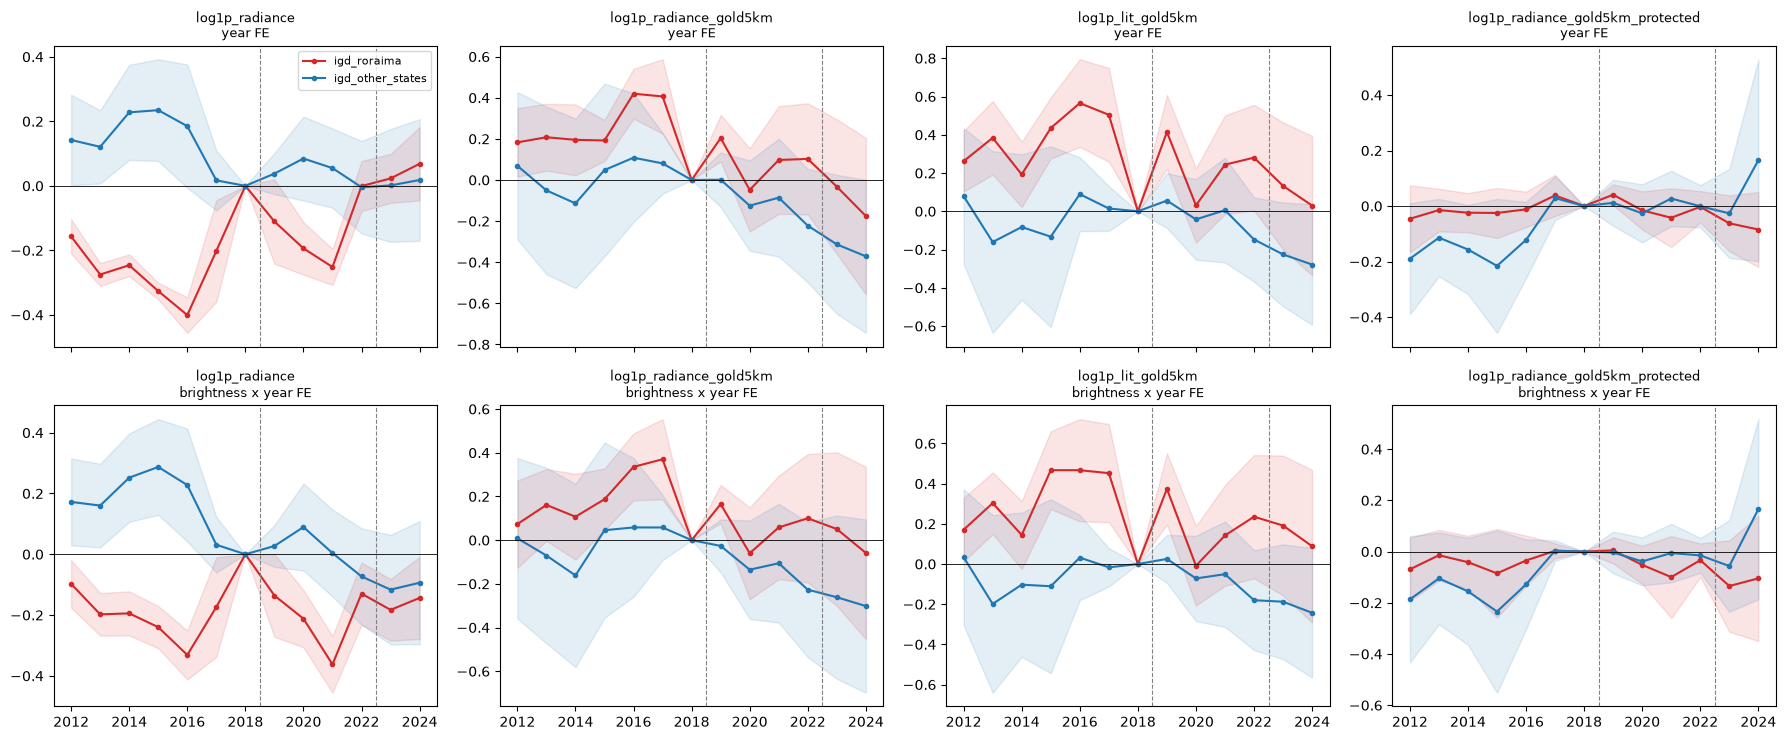

fe                year FE                                                                                                                                                                    brightness x year FE                 \
exposure igd_other_states    igd_roraima       igd_other_states            igd_roraima  igd_other_states       igd_roraima                 igd_other_states                      igd_roraima     igd_other_states    igd_roraima   
outcome    log1p_radiance log1p_radiance log1p_radiance_gold5km log1p_radiance_gold5km log1p_lit_gold5km log1p_lit_gold5km log1p_radiance_gold5km_protected log1p_radiance_gold5km_protected       log1p_radiance log1p_radiance   
year                                                                                                                                                                                                                               
2012                 0.14          -0.16                   0.07                   0.18              0.08              0.26                            -0.19                            -0.05                 0.17           -0.1   
2013                 0.12          -0.27                  -0.05                   0.21             -0.16              0.38                            -0.11                            -0.01                 0.16           -0.2   
2014                 0.23          -0.25                  -0.11                    0.2             -0.08              0.19                            -0.16                            -0.02                 0.25          -0.19   
2015                 0.23          -0.33                   0.05                   0.19             -0.13              0.44                            -0.22                            -0.02                 0.29          -0.24   
2016                 0.18           -0.4                   0.11                   0.42              0.09              0.57                            -0.12                            -0.01                 0.23          -0.33   
2017                 0.02           -0.2                   0.08                   0.41              0.01               0.5                             0.03                             0.04                 0.03          -0.17   
2018                    0              0                      0                      0                 0                 0                                0                                0                    0              0   
2019                 0.04          -0.11                      0                    0.2              0.06              0.41                             0.01                             0.04                 0.03          -0.14   
2020                 0.08          -0.19                  -0.12                  -0.05             -0.04              0.03                            -0.03                            -0.02                 0.09          -0.21   
2021                 0.05          -0.25                  -0.09                    0.1              0.01              0.24                             0.03                            -0.04                    0          -0.36   
2022                   -0             -0                  -0.22                    0.1             -0.15              0.28                               -0                               -0                -0.07          -0.13   
2023                    0           0.02                  -0.31                  -0.03             -0.23              0.13                            -0.03                            -0.06                -0.12          -0.18   
2024                 0.02           0.07                  -0.37                  -0.18             -0.28              0.03                             0.17                            -0.08                -0.09          -0.14   

fe                                                                                                                         

In [4]:
LIGHTS = ["log1p_radiance", "log1p_radiance_gold5km", "log1p_lit_gold5km", "log1p_radiance_gold5km_protected"]
split = pd.concat([
    G.event_study(frame, outcome, exposures=(G.IGD_RORAIMA, G.IGD_OTHER), years=N.YEARS, fe=fe,
                  sample=N.has_pixels(N.zone_of(outcome))).assign(fe=name)
    for name, fe in N.FIXED_EFFECTS.items() for outcome in LIGHTS
], ignore_index=True)
split.to_csv(OUT / "event_study_igd_split.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True)
for row, name in enumerate(N.FIXED_EFFECTS):
    for ax, outcome in zip(axes[row], LIGHTS):
        for exposure, color in ((G.IGD_RORAIMA, "C3"), (G.IGD_OTHER, "C0")):
            part = split[(split.outcome == outcome) & (split.exposure == exposure) & (split.fe == name)]
            ax.plot(part.year, part.estimate, marker="o", ms=3, color=color, label=exposure)
            ax.fill_between(part.year, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se,
                            color=color, alpha=0.12)
        for year in (G.SHIFT_YEAR, G.RECOVERY_YEAR):
            ax.axvline(year - 0.5, color="grey", lw=0.8, ls="--")
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(f"{outcome}\n{name}", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(split.pivot_table(index="year", columns=["fe", "exposure", "outcome"], values="estimate", sort=False).round(2))

**Reading the results.** Light does not follow garimpo in IGD municipalities.
- *IGD elsewhere* (21 municipalities):
  - Light near gold is within ±0.16 of 2018 through 2019. It then falls to −0.37 in 2024
    with year FE and to −0.30 with brightness FE, while their garimpo cases rise to +1.20
    (E12).
  - Light near gold inside barred areas stays within ±0.23, +0.17 in 2024.
- *Roraima's IGD* (6 municipalities):
  - Light near gold rises before the rush (+0.19 to +0.42 in 2015–17), is +0.16 to +0.20 in
    2019, and is between −0.06 and +0.10 at the 2020–22 peak.
  - Lit pixels are +0.37 to +0.41 in 2019, then −0.01 to +0.28.
  - The barred zone near gold is dark in every year.
- *Whole municipality:* no IGD break. Roraima's IGD is below 2018 in most years (down to
  −0.40), before 2019 as after.

## 4. Enforcement presence

Presence × year on 2015–2024, relative to 2018, municipalities with pixels in the zone.

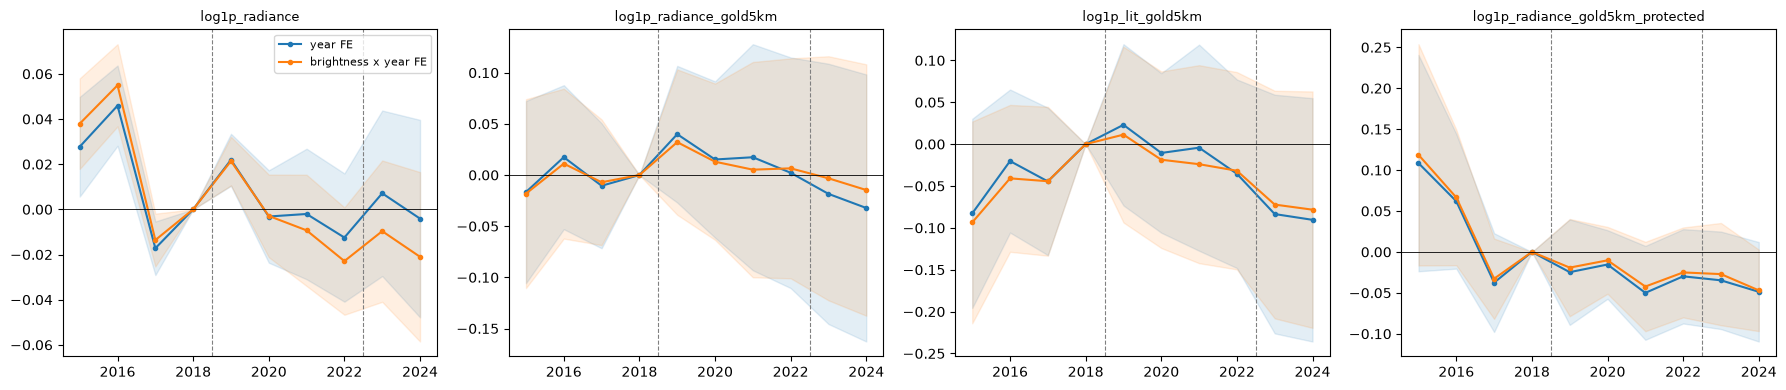

fe             year FE                                                                           brightness x year FE                                                                          
outcome log1p_radiance log1p_radiance_gold5km log1p_lit_gold5km log1p_radiance_gold5km_protected       log1p_radiance log1p_radiance_gold5km log1p_lit_gold5km log1p_radiance_gold5km_protected
year                                                                                                                                                                                           
2015             0.028                 -0.017            -0.083                            0.109                0.038                 -0.018            -0.093                            0.119
2016             0.046                  0.017             -0.02                            0.062                0.055                  0.011            -0.041                            0.067
2017            -0.017                 -0.011            -0.045                           -0.037               -0.014                 -0.007            -0.044                           -0.033
2018                 0                      0                 0                                0                    0                      0                 0                                0
2019             0.022                   0.04             0.023                           -0.025                0.021                  0.032             0.011                           -0.019
2020            -0.003                  0.015            -0.011                           -0.015               -0.003                  0.013            -0.019                            -0.01
2021            -0.002                  0.017            -0.004                            -0.05               -0.009                  0.005            -0.024                           -0.042
2022            -0.012                  0.002            -0.035                            -0.03               -0.023                  0.007            -0.032                           -0.025
2023             0.007                 -0.018            -0.084                           -0.035                -0.01                 -0.003            -0.072                           -0.027
2024            -0.004                 -0.032             -0.09                           -0.049               -0.021                 -0.015            -0.078                           -0.047

In [5]:
studies = pd.concat([
    G.event_study(frame, outcome, fe=fe, sample=N.has_pixels(N.zone_of(outcome))).assign(fe=name)
    for name, fe in N.FIXED_EFFECTS.items() for outcome in LIGHTS
], ignore_index=True)
studies.to_csv(OUT / "event_study_presence.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True)
for ax, outcome in zip(axes, LIGHTS):
    for name, color in zip(N.FIXED_EFFECTS, ("C0", "C1")):
        part = studies[(studies.outcome == outcome) & (studies.fe == name)]
        ax.plot(part.year, part.estimate, marker="o", ms=3, color=color, label=name)
        ax.fill_between(part.year, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color,
                        alpha=0.12)
    for year in (G.SHIFT_YEAR, G.RECOVERY_YEAR):
        ax.axvline(year - 0.5, color="grey", lw=0.8, ls="--")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(outcome, fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
display(studies.pivot_table(index="year", columns=["fe", "outcome"], values="estimate", sort=False).round(3))

**Reading the results.** Presence does not move light.
- Light near gold is within ±0.04 of 2018 in every year.
- Lit pixels near gold are −0.03 to −0.09 in 2015 and 2022–24, in both specifications.
- Nothing follows the 2019 drop in fines or their 2023 recovery.

## 5. The 2019 and 2023 terms

In [6]:
table = N.run_table(frame)
table.to_csv(OUT / "dates.csv", index=False)
for term in ("post2019", "post2023"):
    part = table[table.term == term]
    for value in ("estimate", "p_basin", "p_wcb"):
        print(term, value)
        display(part.pivot_table(index=["design", "fe"], columns="outcome", values=value, sort=False).round(3))
table[["design", "outcome", "n_obs", "n_municipalities", "n_basins"]].drop_duplicates(["design", "outcome"])

post2019 estimate


outcome                        log1p_radiance  log1p_radiance_gold5km  log1p_radiance_protected  log1p_radiance_gold5km_protected  log1p_lit  log1p_lit_gold5km  log1p_lit_protected  log1p_lit_gold5km_protected
design   fe                                                                                                                                                                                                      
IGD      year FE                       -0.046                  -0.129                     0.165                             0.083     -0.067             -0.022                0.084                        0.064
         brightness x year FE          -0.119                  -0.114                     0.168                             0.073     -0.129             -0.033                0.073                        0.016
presence year FE                       -0.013                   0.021                    -0.043                            -0.063      0.031               0.03               -0.039                       -0.074
         brightness x year FE          -0.023                   0.018                    -0.045                            -0.062      0.021              0.029                -0.04                       -0.062

post2019 p_basin


outcome                        log1p_radiance  log1p_radiance_gold5km  log1p_radiance_protected  log1p_radiance_gold5km_protected  log1p_lit  log1p_lit_gold5km  log1p_lit_protected  log1p_lit_gold5km_protected
design   fe                                                                                                                                                                                                      
IGD      year FE                        0.413                    0.34                      0.08                             0.126      0.072              0.861                0.454                        0.345
         brightness x year FE           0.054                   0.412                       0.1                             0.324      0.007              0.794                0.546                        0.817
presence year FE                          0.3                   0.613                     0.041                             0.158      0.014              0.435                0.123                        0.143
         brightness x year FE           0.021                   0.649                     0.044                             0.167      0.018              0.425                0.129                        0.177

post2019 p_wcb


...

post2023 p_basin


outcome                        log1p_radiance  log1p_radiance_gold5km  log1p_radiance_protected  log1p_radiance_gold5km_protected  log1p_lit  log1p_lit_gold5km  log1p_lit_protected  log1p_lit_gold5km_protected
design   fe                                                                                                                                                                                                      
IGD      year FE                        0.804                   0.024                     0.192                             0.688      0.384              0.027                 0.21                        0.785
         brightness x year FE           0.188                   0.212                     0.117                             0.636       0.09              0.169                0.159                        0.709
presence year FE                        0.965                   0.234                     0.201                             0.616      0.136              0.084                0.234                        0.915
         brightness x year FE           0.313                   0.558                     0.185                             0.511      0.229              0.209                0.179                        0.831

post2023 p_wcb


outcome                        log1p_radiance  log1p_radiance_gold5km  log1p_radiance_protected  log1p_radiance_gold5km_protected  log1p_lit  log1p_lit_gold5km  log1p_lit_protected  log1p_lit_gold5km_protected
design   fe                                                                                                                                                                                                      
IGD      year FE                        0.811                   0.018                      0.23                             0.696      0.449              0.019                0.254                        0.814
         brightness x year FE           0.213                   0.231                      0.15                             0.651      0.122               0.18                0.197                        0.758
presence year FE                        0.964                   0.276                     0.199                             0.646      0.146              0.143                0.239                         0.91
         brightness x year FE           0.331                   0.585                      0.18                             0.523       0.23               0.28                0.177                        0.833

,design,outcome,n_obs,n_municipalities,n_basins
0,IGD,log1p_radiance,10036,772,143
2,IGD,log1p_radiance_gold5km,2379,183,59
4,IGD,log1p_radiance_protected,4940,380,116
6,IGD,log1p_radiance_gold5km_protected,858,66,31
8,IGD,log1p_lit,10036,772,143
10,IGD,log1p_lit_gold5km,2379,183,59
12,IGD,log1p_lit_protected,4940,380,116
14,IGD,log1p_lit_gold5km_protected,858,66,31
32,presence,log1p_radiance,7720,772,143
34,presence,log1p_radiance_gold5km,1830,183,59


**Reading the results.** No date shows in light once the composite shocks are absorbed.
- *IGD × post-2019:*
  - Radiance near gold −0.13 / −0.11 (p 0.34 / 0.41).
  - Inside barred areas +0.17 (p 0.08 / 0.10).
  - Whole municipality with brightness FE: radiance −0.12 (p 0.054) and lit −0.13
    (p 0.007), a fall, not a rise.
- *IGD × post-2023:*
  - Near gold, year FE: radiance −0.22 (Otto-3 p 0.024, bootstrap 0.018), lit −0.21
    (p 0.027).
  - With brightness FE: −0.14 and −0.13 (p 0.21 and 0.17). Part of the year-FE estimate
    is the 2023 jump in dim municipalities.
  - The event study shows the fall starting in 2020, not 2023.
- *Presence × post-2019:*
  - Near gold: +0.02 to +0.03 (p 0.43–0.65).
  - Whole municipality: radiance −0.02 (p 0.02 with brightness FE) and lit +0.02 to
    +0.03 (p 0.014–0.018), tiny and of opposite sign.
  - Barred areas: −0.04 (p 0.04).
- *Presence × post-2023:* nothing.
- Light gives no evidence on E11's or E12's dates. It also fails the measurement check
  (sections 1–2), so these nulls say nothing about garimpo.